## How Many Drivers Who Start in the Top 10 also Finish in the Top 10?

#### Step 1: Get the Data

Use pynascar to get the drivers starting in the top 10 and their finishing positions. Then compute the calculation

In [1]:
from pynascar import Race

#create function to get the calculation for a race

def race_data(race_id=5596):
    # start with one race - daytona 500 2026
    try:
        race = Race(year=2026, series_id=1, race_id=race_id, reload=True)
    except:
        return

    df = race.results.results

    df['stayed_top_10'] = (df['starting_position'] > 0) & (df['starting_position'] < 11) & (df['finishing_position'] > 0) & (df['finishing_position'] < 11)

    return df['stayed_top_10'].sum()/10

In [2]:
# loop through all races in 2026 season
percent_list = []
for i in range(5596, 5628):
    percent_list.append(race_data(i))

Fetching Data for 2026-1-5596
Fetching Data for 2026-1-5597
Fetching Data for 2026-1-5598
Fetching Data for 2026-1-5599
Fetching Data for 2026-1-5600
Fetching Data for 2026-1-5601
Fetching Data for 2026-1-5602
Fetching Data for 2026-1-5603
Fetching Data for 2026-1-5604
Fetching Data for 2026-1-5605
Fetching Data for 2026-1-5606
Fetching Data for 2026-1-5607
Fetching Data for 2026-1-5608
Failed to fetch data for https://cf.nascar.com/cacher/2026/1/5608/weekend-feed.json. Error: 403 Client Error: Forbidden for url: https://cf.nascar.com/cacher/2026/1/5608/weekend-feed.json
Failed to fetch race data for: 2026-1-5608
Failed to fetch data for https://cf.nascar.com/cacher/2026/1/5608/lap-times.json. Error: 403 Client Error: Forbidden for url: https://cf.nascar.com/cacher/2026/1/5608/lap-times.json
Failed to fetch data for https://cf.nascar.com/cacher/2026/1/5608/live-pit-data.json. Error: 403 Client Error: Forbidden for url: https://cf.nascar.com/cacher/2026/1/5608/live-pit-data.json
Failed 

In [37]:
clean_percent_list = [item for item in percent_list if item is not None]
print(clean_percent_list)

[np.float64(0.3), np.float64(0.3), np.float64(0.7), np.float64(0.4), np.float64(0.7), np.float64(0.7), np.float64(0.4), np.float64(0.6), np.float64(0.2), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.3), np.float64(0.5), np.float64(0.5), np.float64(0.3), np.float64(0.8), np.float64(0.3), np.float64(0.6), np.float64(0.5), np.float64(0.3), np.float64(0.4), np.float64(0.4), np.float64(0.5), np.float64(0.5), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.6), np.float64(0.7)]


In [38]:
import numpy as np
driver_count_list = np.array(clean_percent_list)
driver_count_list = driver_count_list * 10
print(driver_count_list)

[3. 3. 7. 4. 7. 7. 4. 6. 2. 6. 7. 8. 3. 5. 5. 3. 8. 3. 6. 5. 3. 4. 4. 5.
 5. 2. 3. 4. 6. 7.]


In [39]:
print(f"On average, {round(sum(driver_count_list)/len(driver_count_list),1)} drivers who start in the top 10 also finish in the top 10")
print("*Note: Data available for", len(clean_percent_list), "out of", len(percent_list), "races of the 2026 season")

On average, 4.8 drivers who start in the top 10 also finish in the top 10
*Note: Data available for 30 out of 32 races of the 2026 season


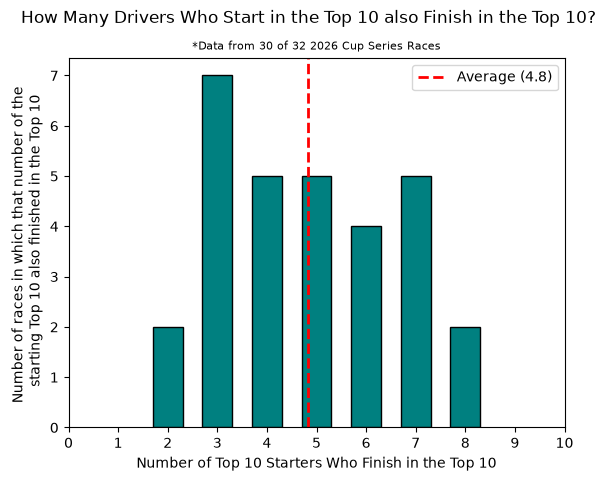

In [44]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

counts = Counter(driver_count_list)

categories = list(counts.keys())
frequencies = list(counts.values())

plt.bar(categories, frequencies, color='teal', edgecolor='black', width = .6)

full_range = range(0, 11, 1)

plt.xticks(full_range)
plt.axvline(x=np.mean(driver_count_list), color='red', linestyle='--', linewidth=2, label=f'Average ({np.mean(driver_count_list):.1f})')
plt.legend()
plt.xlabel('Number of Top 10 Starters Who Finish in the Top 10')
plt.ylabel('Number of races in which that number of the \n starting Top 10 also finished in the Top 10')
plt.suptitle('How Many Drivers Who Start in the Top 10 also Finish in the Top 10?', fontsize=12)
plt.title('*Data from 30 of 32 2026 Cup Series Races', fontsize=8)
plt.show()